In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import arabic_reshaper
from bidi.algorithm import get_display

In [31]:
df_branches = pd.read_csv('data/branches.csv')
df_sales = pd.read_csv('data/sales_orders.csv')

In [32]:
df_sales.shape

(540000, 13)

In [33]:
df_sales.columns

Index(['sales_order_id', 'order_date', 'branch_id', 'customer_id',
       'sales_channel', 'payment_method', 'items_count', 'gross_EGP',
       'discount_EGP', 'net_before_tax_EGP', 'tax_EGP', 'paid_total_EGP',
       'status'],
      dtype='object')

In [34]:
df_branches['opening_date'] = pd.to_datetime(df_branches['opening_date'])
df_sales['order_date'] = pd.to_datetime(df_sales['order_date'])

In [35]:
df = df_branches.merge(
    df_sales,
    on='branch_id',
    how='left'
)

In [36]:
df.shape

(540000, 19)

In [37]:
df = df[df['order_date'] >= df['opening_date']]

In [38]:
df.shape

(501960, 19)

In [39]:
df.head()

,branch_id,branch_name_ar,governorate_ar,city_ar,address_ar,retail_location_type,opening_date,sales_order_id,order_date,customer_id,sales_channel,payment_method,items_count,gross_EGP,discount_EGP,net_before_tax_EGP,tax_EGP,paid_total_EGP,status
479,BR001,الزمالك,القاهرة,الزمالك,شارع 26 يوليو، الزمالك,Point of sale / reseller,2019-09-14,SO00038443,2019-09-14,C0007960,E-commerce,Card POS,2,212.12,17.12,195.00,27.30,222.30,Completed
480,BR001,الزمالك,القاهرة,الزمالك,شارع 26 يوليو، الزمالك,Point of sale / reseller,2019-09-14,SO00038613,2019-09-16,C0005189,Retail POS,Cash,2,299.18,2.80,296.38,41.49,337.87,Completed
481,BR001,الزمالك,القاهرة,الزمالك,شارع 26 يوليو، الزمالك,Point of sale / reseller,2019-09-14,SO00038644,2019-09-16,C0003225,Retail POS,Card POS,1,59.84,5.98,53.86,7.54,61.40,Completed
482,BR001,الزمالك,القاهرة,الزمالك,شارع 26 يوليو، الزمالك,Point of sale / reseller,2019-09-14,SO00038743,2019-09-17,C0005263,Retail POS,Cash,2,347.63,34.76,312.87,43.80,356.67,Completed
483,BR001,الزمالك,القاهرة,الزمالك,شارع 26 يوليو، الزمالك,Point of sale / reseller,2019-09-14,SO00038852,2019-09-18,NaN,Retail POS,Card POS,1,75.91,7.59,68.32,9.56,77.88,Completed


In [40]:
df.describe()

,opening_date,order_date,items_count,gross_EGP,discount_EGP,net_before_tax_EGP,tax_EGP,paid_total_EGP
count,501960,501960,501960.000000,501960.000000,501960.000000,501960.000000,501960.000000,501960.000000
mean,2019-08-24 00:24:38.211809792,2023-10-07 15:51:11.575424256,2.108246,1713.441731,73.907407,1639.534324,229.534889,1869.069213
min,2018-11-06 00:00:00,2018-11-06 00:00:00,1.000000,14.620000,0.000000,12.430000,1.740000,14.170000
25%,2019-03-09 00:00:00,2022-03-12 00:00:00,1.000000,328.267500,0.000000,313.830000,43.940000,357.770000
50%,2019-08-06 00:00:00,2024-01-13 00:00:00,2.000000,762.205000,19.630000,728.835000,102.040000,830.875000
75%,2020-01-12 00:00:00,2025-07-03 00:00:00,3.000000,1752.472500,64.840000,1675.947500,234.632500,1910.580000
max,2020-08-29 00:00:00,2026-10-18 00:00:00,5.000000,244799.340000,48794.940000,210446.070000,29462.450000,239908.520000
std,NaN,NaN,1.007356,3679.115666,242.150470,3523.001484,493.220214,4016.221698


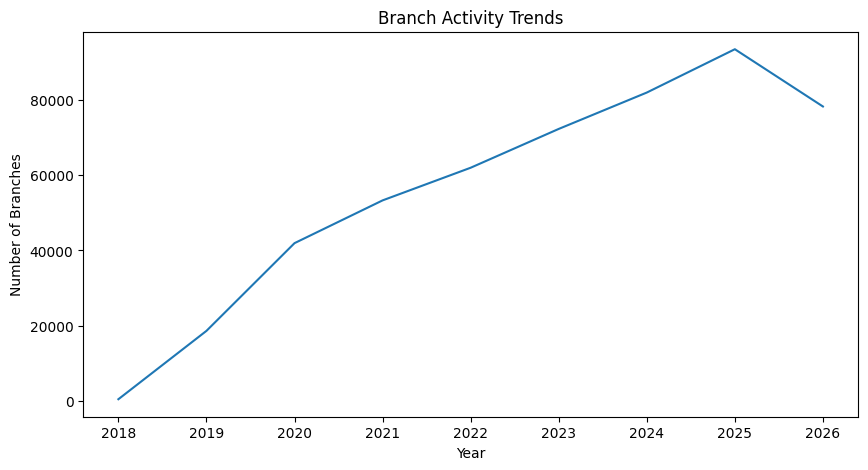

In [41]:
df.groupby(df['order_date'].dt.year)['branch_id'].count().plot(kind='line', figsize=(10, 5))
plt.xlabel('Year')
plt.ylabel('Number of Branches')
plt.title('Branch Activity Trends')
plt.show()

In [42]:
df_eliminated = df[
    (df['order_date'].dt.month < 10) |
    (
        (df['order_date'].dt.month == 10) &
        (df['order_date'].dt.day <= 18)
    )
]

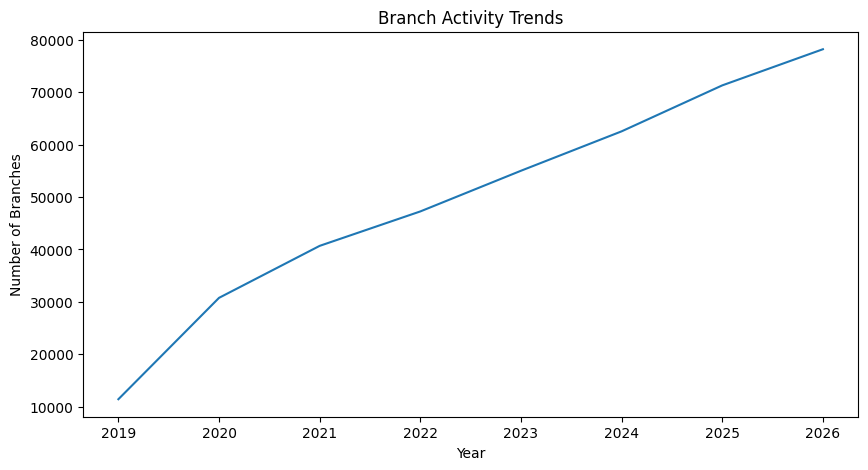

In [43]:
df_eliminated.groupby(df_eliminated['order_date'].dt.year)['branch_id'].count().plot(kind='line', figsize=(10, 5))
plt.xlabel('Year')
plt.ylabel('Number of Branches')
plt.title('Branch Activity Trends')
plt.show()

In [44]:
df_returns = pd.read_csv('data/sales_returns.csv')

In [45]:
df = df.merge(df_returns , on ='sales_order_id' , how = 'left')

In [46]:
df.columns

Index(['branch_id', 'branch_name_ar', 'governorate_ar', 'city_ar',
       'address_ar', 'retail_location_type', 'opening_date', 'sales_order_id',
       'order_date', 'customer_id', 'sales_channel', 'payment_method',
       'items_count', 'gross_EGP', 'discount_EGP', 'net_before_tax_EGP',
       'tax_EGP', 'paid_total_EGP', 'status', 'return_id', 'sales_line_id',
       'return_date', 'sku_id', 'return_quantity', 'refund_amount_EGP',
       'reason', 'refund_method'],
      dtype='object')

In [47]:
df.return_id = [1 if pd.notnull(x) else 0 for x in df.return_id]

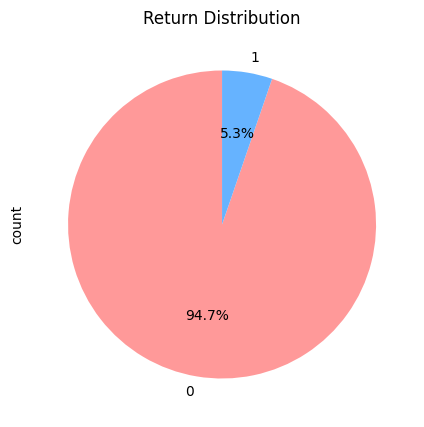

In [48]:
df.return_id.value_counts().plot(kind='pie', figsize=(10, 5),autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff'])
plt.title('Return Distribution')
plt.show()

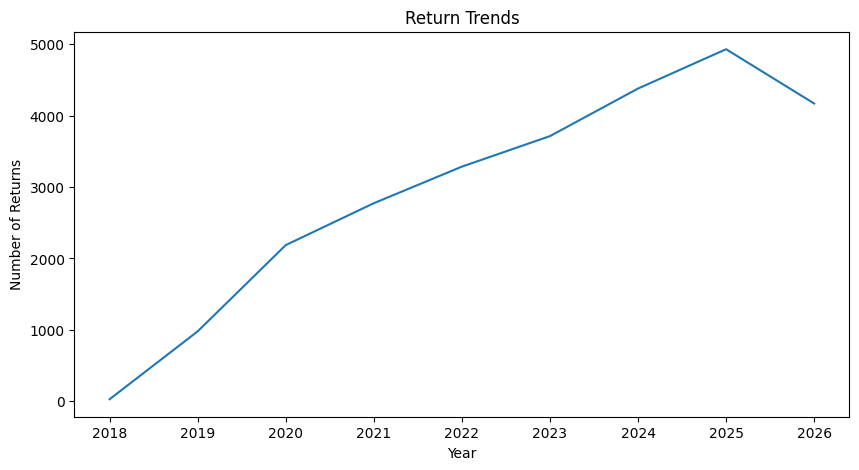

In [49]:
df.groupby(df['order_date'].dt.year)['return_id'].sum().plot(kind='line', figsize=(10, 5))
plt.xlabel('Year')
plt.ylabel('Number of Returns')
plt.title('Return Trends')
plt.show()

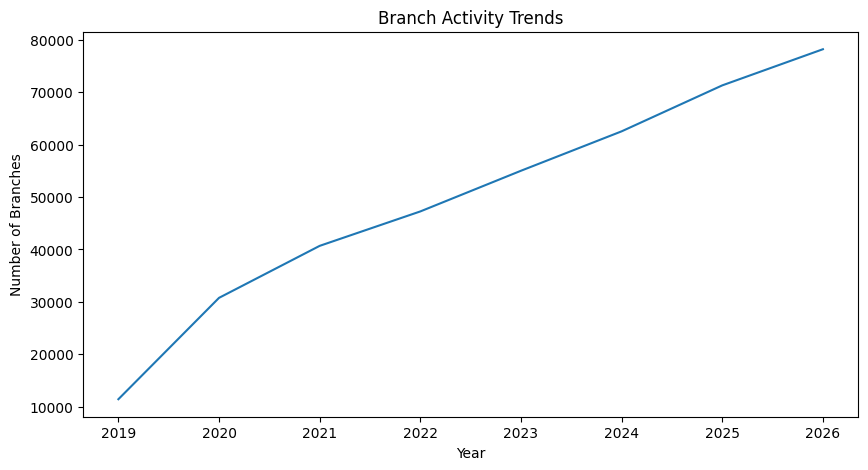

In [50]:
df_eliminated = df[
    (df['order_date'].dt.month < 10) |
    (
        (df['order_date'].dt.month == 10) &
        (df['order_date'].dt.day <= 18)
    )
]

df_eliminated.groupby(df_eliminated['order_date'].dt.year)['branch_id'].count().plot(kind='line', figsize=(10, 5))
plt.xlabel('Year')
plt.ylabel('Number of Branches')
plt.title('Branch Activity Trends')
plt.show()

In [51]:
df.columns

Index(['branch_id', 'branch_name_ar', 'governorate_ar', 'city_ar',
       'address_ar', 'retail_location_type', 'opening_date', 'sales_order_id',
       'order_date', 'customer_id', 'sales_channel', 'payment_method',
       'items_count', 'gross_EGP', 'discount_EGP', 'net_before_tax_EGP',
       'tax_EGP', 'paid_total_EGP', 'status', 'return_id', 'sales_line_id',
       'return_date', 'sku_id', 'return_quantity', 'refund_amount_EGP',
       'reason', 'refund_method'],
      dtype='object')

In [56]:
df_exp = pd.read_csv('data/operating_expenses.csv')
df_exp['expense_date'] = pd.to_datetime(df_exp['expense_date'])

In [57]:
df_exp['Quarter Year'] = df_exp['expense_date'].dt.to_period('Q')

In [58]:
df_exp.head()

,expense_id,expense_date,branch_or_department_id,expense_category,amount_EGP,payment_method,vendor_name,Quarter Year
0,EXP0000001,2018-11-23,WH01,Travel,540.68,Card,Vendor 051,2018Q4
1,EXP0000002,2025-03-18,BR036,General administration,2257.46,Cash,Vendor 197,2025Q1
2,EXP0000003,2025-07-16,BR043,General administration,3602.26,Cash,Vendor 070,2025Q3
3,EXP0000004,2023-10-16,BR075,Utilities,3047.98,Cash,Vendor 195,2023Q4
4,EXP0000005,2018-11-05,BR077,Travel,1192.94,Cash,Vendor 040,2018Q4


In [60]:
df_exp = df_exp.groupby(['branch_or_department_id', 'Quarter Year'])['amount_EGP'].sum().reset_index()
df_exp

,branch_or_department_id,Quarter Year,amount_EGP
0,BR001,2018Q4,9803.22
1,BR001,2019Q1,17759.36
2,BR001,2019Q2,18205.28
3,BR001,2019Q3,18626.40
4,BR001,2019Q4,19065.76
...,...,...,...
3026,WH12,2025Q4,177903.92
3027,WH12,2026Q1,193915.00
3028,WH12,2026Q2,141925.00
3029,WH12,2026Q3,159164.00


In [53]:
df['Quarter Year'] = df['order_date'].dt.to_period('Q')

order_level = (
    df.groupby(
        ['branch_id', 'branch_name_ar', 'governorate_ar',
         'Quarter Year', 'sales_order_id']
    )
    .agg(
        returned=('return_id', 'max'),
        net_profit=('net_before_tax_EGP', 'first')
    )
    .reset_index()
)

In [54]:
quarterly_branch = (
    order_level
    .groupby([
        'branch_id',
        'branch_name_ar',
        'governorate_ar',
        'Quarter Year'
    ])
    .agg(
        Total_Orders=('sales_order_id', 'nunique'),
        Returned_Orders=('returned', 'sum'),
        Completed_Orders=('returned', lambda x: (x == 0).sum()),
        Net_Profit=('net_profit', 'sum')
    )
    .reset_index()
)

In [55]:
quarterly_branch 

,branch_id,branch_name_ar,governorate_ar,Quarter Year,Total_Orders,Returned_Orders,Completed_Orders,Net_Profit
0,BR001,الزمالك,القاهرة,2019Q3,20,0,20,12114.02
1,BR001,الزمالك,القاهرة,2019Q4,164,8,156,67623.78
2,BR001,الزمالك,القاهرة,2020Q1,134,9,125,71944.08
3,BR001,الزمالك,القاهرة,2020Q2,164,13,151,88367.04
4,BR001,الزمالك,القاهرة,2020Q3,119,2,117,65092.38
...,...,...,...,...,...,...,...,...
2379,BR080,الجامعة,أسيوط,2025Q4,325,21,304,988395.25
2380,BR080,الجامعة,أسيوط,2026Q1,306,23,283,1070715.63
2381,BR080,الجامعة,أسيوط,2026Q2,327,14,313,998660.38
2382,BR080,الجامعة,أسيوط,2026Q3,270,11,259,1031069.57


In [61]:
branches = quarterly_branch.merge(
    df_exp,
    left_on=['branch_id', 'Quarter Year'],
    right_on=['branch_or_department_id', 'Quarter Year'],
    how='left'
)

In [62]:
branches.columns

Index(['branch_id', 'branch_name_ar', 'governorate_ar', 'Quarter Year',
       'Total_Orders', 'Returned_Orders', 'Completed_Orders', 'Net_Profit',
       'branch_or_department_id', 'amount_EGP'],
      dtype='object')

In [63]:
branches.drop(columns=['branch_or_department_id'], inplace=True)

In [64]:
branches.columns

Index(['branch_id', 'branch_name_ar', 'governorate_ar', 'Quarter Year',
       'Total_Orders', 'Returned_Orders', 'Completed_Orders', 'Net_Profit',
       'amount_EGP'],
      dtype='object')

In [67]:
quarterly_overall = (
    branches.groupby('Quarter Year')
    .agg(
        Total_Orders=('Total_Orders', 'sum'),
        Returned_Orders=('Returned_Orders', 'sum'),
        Completed_Orders=('Completed_Orders', 'sum'),
        Net_Profit=('Net_Profit', 'sum'),
        Amount=('amount_EGP', 'sum')
    )
    .reset_index()
    .sort_values('Quarter Year')
)

In [68]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(
    go.Bar(
        x=quarterly_overall['Quarter Year'].astype(str),
        y=quarterly_overall['Net_Profit'],
        name='Net Profit',
        marker_color='steelblue',
        yaxis='y'
    )
)

fig.add_trace(
    go.Scatter(
        x=quarterly_overall['Quarter Year'].astype(str),
        y=quarterly_overall['Total_Orders'],
        name='Total Orders',
        mode='lines+markers',
        line=dict(color='orange', width=3),
        yaxis='y2'
    )
)

fig.update_layout(
    title='Overall Quarterly Business Performance',

    xaxis=dict(title='Quarter'),

    yaxis=dict(
        title='Net Profit (EGP)',
        side='left'
    ),

    yaxis2=dict(
        title='Total Orders',
        overlaying='y',
        side='right'
    ),

    hovermode='x unified',
    template='plotly_white',
    legend=dict(
        orientation='h',
        y=-0.2
    )
)

fig.show()

In [69]:
fig = go.Figure()

# Net Profit - Bar Chart
fig.add_trace(
    go.Bar(
        x=quarterly_overall['Quarter Year'].astype(str),
        y=quarterly_overall['Net_Profit'],
        name='Net Profit',
        marker_color='steelblue',
        yaxis='y'
    )
)

# Amount EGP - Line Chart
fig.add_trace(
    go.Scatter(
        x=quarterly_overall['Quarter Year'].astype(str),
        y=quarterly_overall['Amount'],
        name='Amount EGP',
        mode='lines+markers',
        line=dict(color='orange', width=3),
        yaxis='y2'
    )
)

fig.update_layout(
    title='Quarterly Net Profit vs Amount EGP',

    xaxis=dict(title='Quarter'),

    yaxis=dict(
        title='Net Profit (EGP)',
        side='left'
    ),

    yaxis2=dict(
        title='Amount EGP',
        overlaying='y',
        side='right'
    ),

    hovermode='x unified',
    template='plotly_white',
    legend=dict(
        orientation='h',
        y=-0.2
    )
)

fig.show()

In [72]:
import pandas as pd

# Calculate completed orders ratio
branches['Completed_Ratio'] = (
    branches['Completed_Orders'] / branches['Total_Orders']
)

branches['amount_to_Net_Profit_Ratio'] = (
    branches['amount_EGP'] / branches['Net_Profit']
)

# Sort branches within each quarter based on priorities
branches = branches.sort_values(
    by=[
        'Quarter Year',
        'Net_Profit',
        'Completed_Ratio',
        'amount_to_Net_Profit_Ratio'
    ],
    ascending=[
        True,   # Quarter
        False,  # Higher Net Profit
        False,  # Higher Completed Ratio
        True    # Lower Amount
    ]
)

# Assign rank within each quarter
branches['Branch_Rank'] = (
    branches.groupby('Quarter Year').cumcount() + 1
)

In [75]:
branches.to_csv('data/branch_ranks.csv', index=False)